
# Genetic Variant Classifications

---

## 1. Dataset Source

**Dataset Name:** Genetic Variant Classifications (ClinVar Conflicting Classifications)

**Source:** Kaggle

**Dataset Link:** [Genetic Variant Classifications – Kaggle](https://www.kaggle.com/datasets/kevinarvai/clinvar-conflicting)

---

## 2. Dataset Description

The dataset focuses on genetic variants in human DNA.

The aim of this research is to investigate whether there is a relationship between different characteristics of genetic variants and the presence of conflicting classifications regarding their clinical significance.

The dataset was downloaded from **Kaggle** and is based on data from **ClinVar**, a database maintained by the National Center for Biotechnology Information (NCBI) in the United States. ClinVar collects information about genetic variants and their clinical significance, submitted by laboratories, researchers, and medical organizations.

---

## 3. Why I Chose This Dataset

I chose the topic of genetics because I am very interested in medical research, especially in the study of genetics and its effects on the human body.

In my opinion, one of the most interesting aspects of medicine is trying to understand how our bodies work, what causes different diseases to develop, and how scientific knowledge can be used to detect, treat, and perhaps even prevent diseases in the future.

In addition, I am interested in the possibility of combining medical research and genetics with data science, using statistical tools and data analysis to explore medical and biological questions, identify patterns, and discover new insights.

Therefore, I chose a dataset that allows me to combine a field that personally interests me with the tools I am learning in this course.

---

## 4. Research Questions

The three research questions I would like to investigate using this dataset are:

1. Are different types of genetic variants associated with different diseases?

2. Do rare genetic variants tend to have higher predicted harmfulness scores compared to common genetic variants?

3. Is there a relationship between the frequency of a genetic variant in the population and the presence of conflicting clinical classifications?


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import zipfile
import pandas as pd

with zipfile.ZipFile('/content/drive/MyDrive/archive.zip', 'r') as zip_ref:
    zip_ref.extractall()

df = pd.read_csv('clinvar_conflicting.csv', low_memory=False)

In [19]:
#3. Getting to Know the Data (10 points)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 65188
Number of columns: 46


In [9]:
# Descriptions of the variables
descriptions = {
    "CHROM": "Chromosome",
    "POS": "Position on the chromosome",
    "REF": "Reference allele",
    "ALT": "Alternative allele",
    "AF_ESP": "Allele frequency in ESP",
    "AF_EXAC": "Allele frequency in ExAC",
    "AF_TGP": "Allele frequency in 1000 Genomes",
    "CLNDISDB": "Clinical condition database identifiers",
    "CLNDISDBINCL": "Condition identifiers for included variants",
    "CLNDN": "Associated clinical conditions",
    "CLNDNINCL": "Conditions for included variants",
    "CLNHGVS": "HGVS variant description",
    "CLNSIGINCL": "Clinical significance of included variants",
    "CLNVC": "Type of genetic variant",
    "CLNVI": "Additional variant identifiers",
    "MC": "Molecular consequences",
    "ORIGIN": "Reported variant origin",
    "SSR": "Suspect reason codes",
    "CLASS": "Conflicting clinical classifications (0 = No, 1 = Yes)",
    "Allele": "Variant allele identifier",
    "Consequence": "Predicted molecular consequence",
    "IMPACT": "Predicted impact of the variant",
    "SYMBOL": "Gene symbol",
    "Feature_type": "Type of genomic feature",
    "Feature": "Genomic feature identifier",
    "BIOTYPE": "Transcript biotype",
    "EXON": "Exon location",
    "INTRON": "Intron location",
    "HGVSc": "Coding DNA variant notation",
    "HGVSp": "Protein variant notation",
    "cDNA_position": "Position in cDNA",
    "CDS_position": "Position in coding sequence",
    "Protein_position": "Position in protein",
    "Amino_acids": "Amino acid change",
    "Codons": "Codon change",
    "Existing_variation": "Known variant identifiers",
    "DISTANCE": "Distance to nearest feature",
    "STRAND": "DNA strand orientation",
    "FLAGS": "Additional annotation flags",
    "VARIANT_CLASS": "Variant classification",
    "SYMBOL_SOURCE": "Source of gene symbol",
    "HGNC_ID": "HGNC gene identifier",
    "CANONICAL": "Canonical transcript indicator",
    "SIFT": "Predicted protein effect (SIFT)",
    "PolyPhen": "Predicted protein effect (PolyPhen)",
    "MOTIF_NAME": "Sequence motif name",
    "MOTIF_POS": "Position in motif",
    "HIGH_INF_POS": "High-information motif position",
    "MOTIF_SCORE_CHANGE": "Change in motif score",
    "LoFtool": "Loss-of-function intolerance score",
    "CADD_PHRED": "Predicted deleteriousness score (PHRED)",
    "CADD_RAW": "Raw predicted deleteriousness score",
    "BLOSUM62": "Amino acid substitution score"
}

variables_table = pd.DataFrame({
    "Variable": df.columns,
    "Meaning": [
        descriptions.get(column, "Description not available")
        for column in df.columns
    ]
})

display(variables_table)


,Variable,Meaning
0,CHROM,Chromosome
1,POS,Position on the chromosome
2,REF,Reference allele
3,ALT,Alternative allele
4,AF_ESP,Allele frequency in ESP
5,AF_EXAC,Allele frequency in ExAC
6,AF_TGP,Allele frequency in 1000 Genomes
7,CLNDISDB,Clinical condition database identifiers
8,CLNDISDBINCL,Condition identifiers for included variants
9,CLNDN,Associated clinical conditions


In [10]:
data_types = pd.DataFrame({
    "Variable": df.columns,
    "Data Type": df.dtypes.values
})

display(data_types)

,Variable,Data Type
0,CHROM,object
1,POS,int64
2,REF,object
3,ALT,object
4,AF_ESP,float64
5,AF_EXAC,float64
6,AF_TGP,float64
7,CLNDISDB,object
8,CLNDISDBINCL,object
9,CLNDN,object


In [11]:
print("First 5 observations:")
display(df.head())

print("Last 5 observations:")
display(df.tail())

First 5 observations:


,CHROM,POS,REF,ALT,AF_ESP,AF_EXAC,AF_TGP,CLNDISDB,CLNDISDBINCL,CLNDN,...,SIFT,PolyPhen,MOTIF_NAME,MOTIF_POS,HIGH_INF_POS,MOTIF_SCORE_CHANGE,LoFtool,CADD_PHRED,CADD_RAW,BLOSUM62
0,1,1168180,G,C,0.0771,0.10020,0.1066,MedGen:CN169374,NaN,not_specified,...,tolerated,benign,NaN,NaN,NaN,NaN,NaN,1.053,-0.208682,2.0
1,1,1470752,G,A,0.0000,0.00000,0.0000,"MedGen:C1843891,OMIM:607454,Orphanet:ORPHA9877...",NaN,Spinocerebellar_ataxia_21|not_provided,...,deleterious_low_confidence,benign,NaN,NaN,NaN,NaN,NaN,31.000,6.517838,-3.0
2,1,1737942,A,G,0.0000,0.00001,0.0000,"Human_Phenotype_Ontology:HP:0000486,MedGen:C00...",NaN,Strabismus|Nystagmus|Hypothyroidism|Intellectu...,...,deleterious,probably_damaging,NaN,NaN,NaN,NaN,NaN,28.100,6.061752,-1.0
3,1,2160305,G,A,0.0000,0.00000,0.0000,"MedGen:C1321551,OMIM:182212,SNOMED_CT:83092002...",NaN,Shprintzen-Goldberg_syndrome|not_provided,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.500,3.114491,NaN
4,1,2160305,G,T,0.0000,0.00000,0.0000,"MedGen:C1321551,OMIM:182212,SNOMED_CT:83092002",NaN,Shprintzen-Goldberg_syndrome,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.700,4.766224,-3.0


Last 5 observations:


,CHROM,POS,REF,ALT,AF_ESP,AF_EXAC,AF_TGP,CLNDISDB,CLNDISDBINCL,CLNDN,...,SIFT,PolyPhen,MOTIF_NAME,MOTIF_POS,HIGH_INF_POS,MOTIF_SCORE_CHANGE,LoFtool,CADD_PHRED,CADD_RAW,BLOSUM62
65183,X,154158201,T,G,0.0801,0.13923,0.1605,"MedGen:C0019069,OMIM:306700,SNOMED_CT:28293008...",NaN,Hereditary_factor_VIII_deficiency_disease|not_...,...,NaN,NaN,NaN,NaN,NaN,NaN,0.00158,0.105,-0.630908,NaN
65184,X,154159118,C,T,0.0020,0.00060,0.0013,MedGen:CN169374|MedGen:CN239152,NaN,"not_specified|Hemophilia_A,_FVIII_Deficiency",...,tolerated,benign,NaN,NaN,NaN,NaN,0.00158,0.002,-1.731470,3.0
65185,X,154194886,C,T,0.0125,0.00370,0.0111,MedGen:CN169374|MedGen:CN239152,NaN,"not_specified|Hemophilia_A,_FVIII_Deficiency",...,NaN,NaN,NaN,NaN,NaN,NaN,0.00158,12.850,1.412434,NaN
65186,X,154490187,T,C,0.0003,0.00034,0.0000,"MedGen:C3501611,Orphanet:ORPHA777|MedGen:CN169374",NaN,Non-syndromic_X-linked_intellectual_disability...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.130,-0.592415,NaN
65187,X,154508542,G,C,0.0019,0.00267,0.0008,MedGen:CN169374|MedGen:CN517202,NaN,not_specified|not_provided,...,NaN,NaN,NaN,NaN,NaN,NaN,0.14000,0.046,-0.786513,-1.0


In [12]:
display(df.describe())

,POS,AF_ESP,AF_EXAC,AF_TGP,ORIGIN,SSR,CLASS,DISTANCE,STRAND,MOTIF_POS,MOTIF_SCORE_CHANGE,LoFtool,CADD_PHRED,CADD_RAW,BLOSUM62
count,6.518800e+04,65188.000000,65188.000000,65188.000000,65188.000000,130.000000,65188.000000,108.000000,65174.000000,2.0,2.000000,60975.000000,64096.000000,64096.000000,25593.000000
mean,7.757594e+07,0.014511,0.014492,0.015263,1.342486,2.269231,0.252102,825.731481,-0.006659,1.0,-0.080000,0.345058,15.685616,2.554131,-0.402258
std,5.974051e+07,0.057795,0.059542,0.059527,5.688772,4.190777,0.434223,1069.363315,0.999985,0.0,0.024042,0.361238,10.836350,2.961553,1.872684
min,9.610000e+02,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,-1.000000,1.0,-0.097000,0.000069,0.001000,-5.477391,-3.000000
25%,3.254179e+07,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,55.500000,-1.000000,1.0,-0.088500,0.024300,7.141000,0.462951,-2.000000
50%,5.797021e+07,0.000000,0.000040,0.000000,1.000000,1.000000,0.000000,469.000000,-1.000000,1.0,-0.080000,0.157000,14.090000,1.642948,-1.000000
75%,1.127454e+08,0.001200,0.001230,0.001600,1.000000,1.000000,1.000000,1415.000000,1.000000,1.0,-0.071500,0.710000,24.100000,4.381392,1.000000
max,2.476080e+08,0.499000,0.499890,0.499800,513.000000,16.000000,1.000000,4759.000000,1.000000,1.0,-0.063000,1.000000,99.000000,46.556261,3.000000


In [13]:
unique_values = pd.DataFrame({
    "Variable": df.columns,
    "Unique Values": df.nunique().values
})

display(unique_values)

,Variable,Unique Values
0,CHROM,24
1,POS,63115
2,REF,866
3,ALT,458
4,AF_ESP,2842
5,AF_EXAC,6667
6,AF_TGP,2087
7,CLNDISDB,9234
8,CLNDISDBINCL,93
9,CLNDN,9260


**Question 1: Do the data types match the meaning of the variables?**

Not all data types match the meaning of the variables. For example, CLASS is stored as a numerical variable, but it represents a categorical variable with two possible values (0 and 1).

**Question 2: Are there any columns that appear to be unnecessary?**

Yes, some columns appear to be unnecessary for our research questions. For example, CLNHGVS and CLNVI contain detailed variant descriptions and identifiers that may not be relevant to our analysis.

**Question 3: Are there any variables that require data type conversion?**

Yes, some variables may benefit from data type conversion. For example, CLASS and ORIGIN are stored as numerical variables, but they represent categorical information. Therefore, they could be converted to the category data type.

**Question 4: Did you discover anything surprising during the initial data exploration?**

Yes, I was surprised by the large difference between the mean and median of AF_EXAC, suggesting that many genetic variants have very low frequencies, while some have much higher frequencies. I also noticed that some columns contain a large number of missing values.

In [21]:
#4.1 Missing Data
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing_values)

,Missing Count,Missing Percentage
CHROM,0,0.000000
POS,0,0.000000
REF,0,0.000000
ALT,0,0.000000
AF_ESP,0,0.000000
AF_EXAC,0,0.000000
AF_TGP,0,0.000000
CLNDISDB,0,0.000000
CLNDISDBINCL,65021,99.743818
CLNDN,0,0.000000


In [15]:
group_columns = ["IMPACT", "CLASS", "CLNVC"]
missing_columns = df.columns[df.isnull().any()]

for group in group_columns:
    print("Missing values by:", group)

    missing_by_group = df.groupby(group)[missing_columns].apply(
        lambda x: x.isnull().mean() * 100
    )

    display(missing_by_group.round(2))

Missing values by: IMPACT


,CLNDISDBINCL,CLNDNINCL,CLNSIGINCL,CLNVI,MC,SSR,SYMBOL,Feature_type,Feature,BIOTYPE,...,SIFT,PolyPhen,MOTIF_NAME,MOTIF_POS,HIGH_INF_POS,MOTIF_SCORE_CHANGE,LoFtool,CADD_PHRED,CADD_RAW,BLOSUM62
IMPACT,,,,,,,,,,,,,,,,,,,,,
HIGH,99.60,99.60,99.60,70.81,0.86,99.92,0.00,0.00,0.00,0.00,...,98.32,98.25,100.00,100.00,100.00,100.00,4.90,15.59,15.59,98.02
LOW,99.97,99.97,99.97,55.06,0.03,99.74,0.00,0.00,0.00,0.00,...,100.00,100.00,100.00,100.00,100.00,100.00,7.06,0.18,0.18,100.00
MODERATE,99.59,99.59,99.59,58.92,2.11,99.81,0.00,0.00,0.00,0.00,...,25.46,25.59,100.00,100.00,100.00,100.00,6.08,0.79,0.79,23.22
MODIFIER,99.91,99.91,99.91,48.01,1.77,99.87,0.29,0.25,0.25,0.29,...,100.00,100.00,99.96,99.96,99.96,99.96,7.79,0.93,0.93,100.00


Missing values by: CLASS


,CLNDISDBINCL,CLNDNINCL,CLNSIGINCL,CLNVI,MC,SSR,SYMBOL,Feature_type,Feature,BIOTYPE,...,SIFT,PolyPhen,MOTIF_NAME,MOTIF_POS,HIGH_INF_POS,MOTIF_SCORE_CHANGE,LoFtool,CADD_PHRED,CADD_RAW,BLOSUM62
CLASS,,,,,,,,,,,,,,,,,,,,,
0,99.80,99.80,99.80,61.56,1.21,99.79,0.01,0.01,0.01,0.01,...,62.47,62.50,100.00,100.00,100.00,100.00,6.33,1.97,1.97,61.33
1,99.58,99.58,99.58,45.75,1.55,99.83,0.07,0.05,0.05,0.07,...,60.22,60.37,99.99,99.99,99.99,99.99,6.87,0.79,0.79,58.98


Missing values by: CLNVC


,CLNDISDBINCL,CLNDNINCL,CLNSIGINCL,CLNVI,MC,SSR,SYMBOL,Feature_type,Feature,BIOTYPE,...,SIFT,PolyPhen,MOTIF_NAME,MOTIF_POS,HIGH_INF_POS,MOTIF_SCORE_CHANGE,LoFtool,CADD_PHRED,CADD_RAW,BLOSUM62
CLNVC,,,,,,,,,,,,,,,,,,,,,
Deletion,99.76,99.76,99.76,69.79,21.48,99.92,0.00,0.00,0.00,0.00,...,100.00,100.00,100.0,100.0,100.0,100.0,6.86,23.75,23.75,100.00
Duplication,99.81,99.81,99.81,65.28,18.47,100.00,0.00,0.00,0.00,0.00,...,100.00,100.00,100.0,100.0,100.0,100.0,8.03,24.47,24.47,100.00
Indel,99.60,99.60,99.60,81.78,6.48,99.60,0.00,0.00,0.00,0.00,...,75.30,75.30,100.0,100.0,100.0,100.0,4.86,81.78,81.78,69.23
Insertion,100.00,100.00,100.00,65.26,10.53,100.00,0.00,0.00,0.00,0.00,...,100.00,100.00,100.0,100.0,100.0,100.0,7.37,27.37,27.37,100.00
Inversion,100.00,100.00,100.00,82.35,0.00,100.00,0.00,0.00,0.00,0.00,...,82.35,82.35,100.0,100.0,100.0,100.0,0.00,82.35,82.35,82.35
Microsatellite,100.00,100.00,100.00,40.00,20.00,100.00,0.00,0.00,0.00,0.00,...,100.00,100.00,100.0,100.0,100.0,100.0,20.00,20.00,20.00,100.00
single_nucleotide_variant,99.74,99.74,99.74,56.83,0.15,99.79,0.03,0.02,0.02,0.03,...,59.58,59.64,100.0,100.0,100.0,100.0,6.43,0.00,0.00,58.37


**Suggested Treatment for Missing Values**

The treatment of missing values should depend on the variable and the amount of missing data.

Columns with extremely high percentages of missing values, such as `MOTIF_NAME` (99.997%), could be excluded from the analysis if they are not relevant to our research questions.

For variables such as `SIFT` and `PolyPhen`, missing values should not be automatically replaced because missingness may be related to the type or impact of the genetic variant.

For variables with relatively few missing values, such as `CADD_PHRED` (1.68%), we could consider removing the affected rows from analyses that require this variable.

Important variables such as `AF_EXAC` and `CLASS` contain no missing values and therefore do not require treatment.

This approach helps preserve the reliability of the analysis while avoiding unnecessary data loss.

In [22]:
#4.2 Duplicates
duplicate_rows = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [17]:
duplicate_variants = df.duplicated(
    subset=["CHROM", "POS", "REF", "ALT"]
).sum()

print("Repeated variant identifiers:", duplicate_variants)

Repeated variant identifiers: 0


**4.2 Duplicates**

We checked for duplicate rows using `df.duplicated()` and found no fully duplicated rows.

We also checked for repeated genetic variant identifiers using the combination of `CHROM`, `POS`, `REF`, and `ALT`. No repeated combinations were found.

Therefore, there is no need to remove duplicates from the dataset, since none were detected in these checks. Removing rows unnecessarily could result in the loss of valuable information.

In [25]:
# 4.3 suspicious values

# 1. Check numerical ranges
for col in ["AF_ESP", "AF_EXAC", "AF_TGP"]:
    print(col, "Invalid values:",
          ((df[col] < 0) | (df[col] > 1)).sum())

# 2. Check categorical values
for col in ["CLASS", "IMPACT", "CLNVC", "ORIGIN"]:
    print(col, "Unique values:", df[col].unique())

# 3. Check suspicious default values
for value in [-999, -1, 999, "unknown", "NA", "N/A"]:
    count = df.isin([value]).sum().sum()
    print("Suspicious value", value, ":", count)

    # 4. Check minimum and maximum values in numeric columns
numeric_columns = df.select_dtypes(include="number")
display(numeric_columns.agg(["min", "max"]).T)

AF_ESP Invalid values: 0
AF_EXAC Invalid values: 0
AF_TGP Invalid values: 0
CLASS Unique values: [0 1]
IMPACT Unique values: ['MODERATE' 'MODIFIER' 'LOW' 'HIGH']
CLNVC Unique values: ['single_nucleotide_variant' 'Deletion' 'Duplication' 'Indel' 'Inversion'
 'Insertion' 'Microsatellite']
ORIGIN Unique values: [  1  35  33   5  37   3  32  17  41 513   9   2  57  49   4  65   0  25
  11  13  19  85  43  27  29  16  12 129  21  69  53]
Suspicious value -999 : 0
Suspicious value -1 : 38140
Suspicious value 999 : 0
Suspicious value unknown : 4
Suspicious value NA : 0
Suspicious value N/A : 0


,min,max
POS,961.000000,2.476080e+08
AF_ESP,0.000000,4.990000e-01
AF_EXAC,0.000000,4.998900e-01
AF_TGP,0.000000,4.998000e-01
ORIGIN,0.000000,5.130000e+02
SSR,1.000000,1.600000e+01
CLASS,0.000000,1.000000e+00
DISTANCE,1.000000,4.759000e+03
STRAND,-1.000000,1.000000e+00
MOTIF_POS,1.000000,1.000000e+00


In [26]:
for value in [-1, "unknown"]:
    print("Value:", value)
    print(df.isin([value]).sum()[lambda x: x > 0])

Value: -1
STRAND      32804
BLOSUM62     5336
dtype: int64
Value: unknown
PolyPhen    4
dtype: int64


**4.3 Suspicious Values**

We examined the dataset for impossible values, suspicious default values, and values that do not match the meaning of the variables.

No invalid values were found in `AF_ESP`, `AF_EXAC`, or `AF_TGP`, as all values were within the valid range of 0 to 1. The categorical variables `CLASS`, `IMPACT`, and `CLNVC` also contained expected values.

We also examined the minimum and maximum values of all numerical columns. No clearly impossible values were identified in this examination.

The value `-1` appeared 38,140 times, but further investigation showed that it occurred in `STRAND` and `BLOSUM62`, where negative values are valid.

Additionally, four occurrences of `unknown` were found in `PolyPhen`. These represent unspecified predictions and may require special handling during data cleaning.

Overall, the checks did not reveal clearly impossible numerical values, although some values may require further examination.

In [27]:
# 4.4 Impact of Data Cleaning

# Before cleaning
before = df["PolyPhen"].isna().mean() * 100

# Create a cleaned copy
df_clean = df.copy()
df_clean["PolyPhen"] = df_clean["PolyPhen"].replace("unknown", pd.NA)

# After cleaning
after = df_clean["PolyPhen"].isna().mean() * 100

print("Missing percentage before cleaning:", round(before, 2))
print("Missing percentage after cleaning:", round(after, 2))
print("Difference:", round(after - before, 4))

Missing percentage before cleaning: 61.96
Missing percentage after cleaning: 61.97
Difference: 0.0061


**4.4 Impact of Data Cleaning**

We selected the `PolyPhen` column, which contained four occurrences of the value `unknown`. These values represent unspecified predictions and were replaced with missing values (`NaN`) to ensure consistent representation of missing information.

Before cleaning, the percentage of missing values in `PolyPhen` was 61.96%. After cleaning, it increased slightly to 61.97%, a difference of 0.0061 percentage points.

**Did the cleaning change the overall picture of the data?**

No, the cleaning did not significantly change the overall picture. The percentage of missing values increased only slightly, and `PolyPhen` remained a variable with a high proportion of missing data.

However, the cleaning improved data consistency by correctly identifying the four `unknown` values as missing. No observations were deleted during the process.

In [28]:
# 5. Descriptive Statistics - Numerical Variables

columns = ["AF_EXAC", "CADD_PHRED", "LoFtool"]

stats = df_clean[columns].describe().T

stats["Range"] = stats["max"] - stats["min"]
stats["Variance"] = df_clean[columns].var()
stats["IQR"] = stats["75%"] - stats["25%"]

display(stats.round(4))

,count,mean,std,min,25%,50%,75%,max,Range,Variance,IQR
AF_EXAC,65188.0,0.0145,0.0595,0.0000,0.0000,0.000,0.0012,0.4999,0.4999,0.0035,0.0012
CADD_PHRED,64096.0,15.6856,10.8364,0.0010,7.1410,14.090,24.1000,99.0000,98.9990,117.4265,16.9590
LoFtool,60975.0,0.3451,0.3612,0.0001,0.0243,0.157,0.7100,1.0000,0.9999,0.1305,0.6857


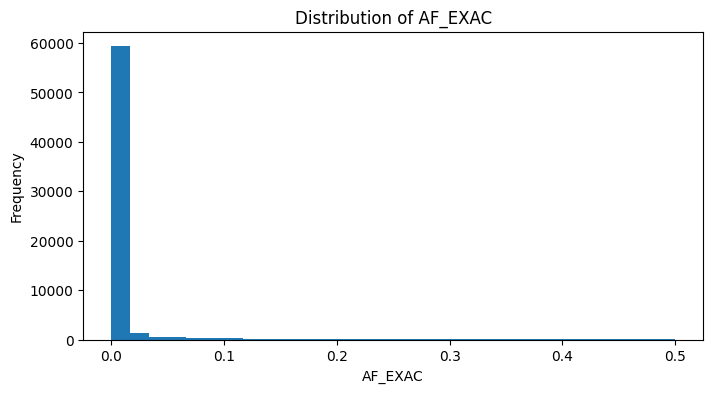

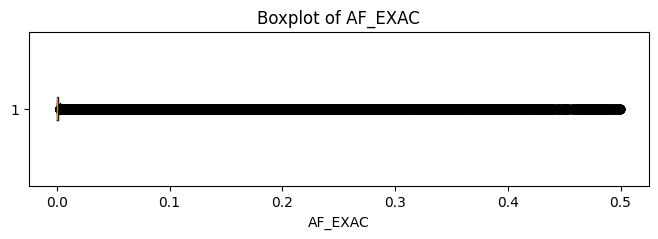

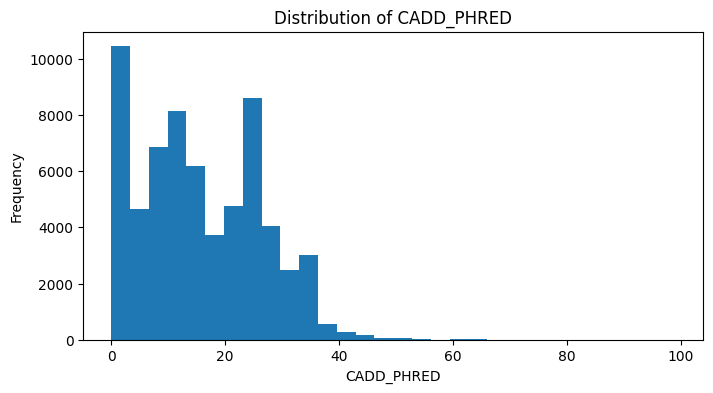

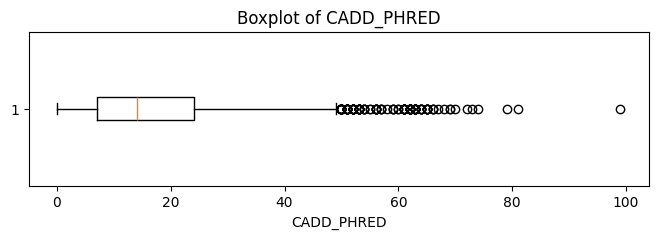

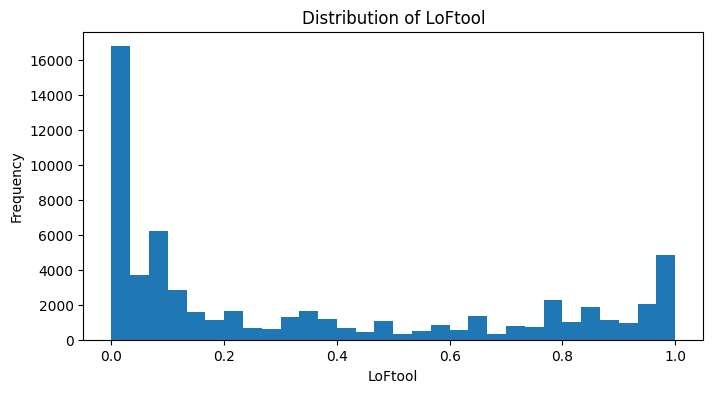

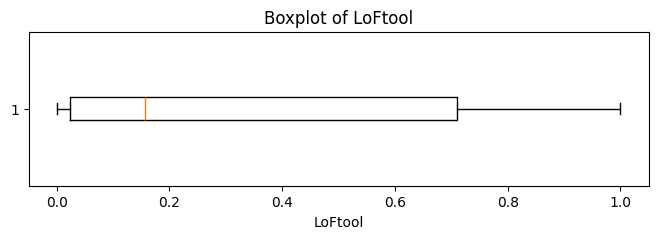

In [29]:
# 5. Visualizations - Numerical Variables

import matplotlib.pyplot as plt

for col in columns:
    # Histogram
    plt.figure(figsize=(8, 4))
    plt.hist(df_clean[col].dropna(), bins=30)
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

    # Boxplot
    plt.figure(figsize=(8, 2))
    plt.boxplot(df_clean[col].dropna(), vert=False)
    plt.title("Boxplot of " + col)
    plt.xlabel(col)
    plt.show()

### Descriptive Statistics and Univariate Analysis – Numerical Variables

We selected three meaningful numerical variables for analysis: `AF_EXAC`, `CADD_PHRED`, and `LoFtool`. We calculated descriptive statistics, including the mean, median, minimum, maximum, range, standard deviation, variance, quartiles, and IQR. We also created histograms and boxplots to examine their distributions.

**AF_EXAC – Population Frequency**

The mean is 0.0145, while the median is very close to zero. The IQR is only 0.0012, indicating that the middle 50% of observations are concentrated within a narrow range.

The histogram shows that most values are concentrated near zero, while the boxplot identifies many statistically unusual higher values. This indicates a strongly right-skewed distribution, suggesting that most genetic variants in the dataset have very low population frequencies.

**CADD_PHRED – Predicted Harmfulness Score**

The mean is 15.69, the median is 14.09, and the standard deviation is 10.84. The IQR is 16.96, indicating considerable variability in predicted harmfulness scores.

The histogram shows that most values are concentrated in the lower and middle ranges, while the boxplot reveals several high outliers. The distribution is right-skewed, with relatively few variants receiving very high scores.

**LoFtool – Gene Loss-of-Function Score**

The mean is 0.3451, the median is 0.157, and the standard deviation is 0.3612. The IQR is 0.6857, indicating substantial variability.

The histogram shows a large concentration of values near zero, as well as another noticeable concentration near one. The boxplot confirms that the middle 50% of observations cover a wide range.

**Overall Conclusion**

The three numerical variables show different distribution patterns. `AF_EXAC` is strongly concentrated near zero, `CADD_PHRED` shows considerable variation with a right-skewed distribution, and `LoFtool` has a wide spread with concentrations near both ends of its range.

These findings provide an initial understanding of the dataset and will help guide further analysis of the relationships between genetic variant frequency, predicted harmfulness, and other genetic characteristics.

In [30]:
# 5. Categorical Variables

categorical_columns = ["CLNVC", "IMPACT", "CLASS"]

for col in categorical_columns:
    print("Variable:", col)

    frequency = df_clean[col].value_counts()
    relative_frequency = df_clean[col].value_counts(normalize=True) * 100

    table = pd.DataFrame({
        "Frequency": frequency,
        "Relative Frequency (%)": relative_frequency
    })

    display(table.round(2))

Variable: CLNVC


,Frequency,Relative Frequency (%)
CLNVC,,
single_nucleotide_variant,61281,94.01
Deletion,2509,3.85
Duplication,1034,1.59
Indel,247,0.38
Insertion,95,0.15
Inversion,17,0.03
Microsatellite,5,0.01


Variable: IMPACT


,Frequency,Relative Frequency (%)
IMPACT,,
MODERATE,33212,50.95
LOW,21642,33.20
MODIFIER,5582,8.56
HIGH,4752,7.29


Variable: CLASS


,Frequency,Relative Frequency (%)
CLASS,,
0,48754,74.79
1,16434,25.21


### Categorical Variables – Frequency Analysis

We analyzed three categorical variables: `CLNVC`, `IMPACT`, and `CLASS`. We calculated the frequency and relative frequency of each category to identify the most common and rare categories.

**CLNVC – Genetic Variant Type**

The most common category is `single_nucleotide_variant`, representing 94.01% of the dataset (61,281 observations). Other variant types are much less common.

Using a threshold of less than 1%, we identified four rare categories: `Indel` (0.38%), `Insertion` (0.15%), `Inversion` (0.03%), and `Microsatellite` (0.01%).

This indicates that the dataset is highly imbalanced in terms of genetic variant types.

**IMPACT – Predicted Impact**

The most common category is `MODERATE` (50.95%), followed by `LOW` (33.20%). The least common category is `HIGH` (7.29%).

Most variants (84.15%) are classified as having moderate or low predicted impact. No categories fall below the 1% rarity threshold.

**CLASS – Conflicting Clinical Classifications**

Most variants belong to `CLASS = 0` (74.79%), meaning they do not have conflicting clinical classifications. The remaining 25.21% belong to `CLASS = 1`, indicating conflicting classifications.

**Overall Conclusion**

The dataset is strongly dominated by single nucleotide variants, while several other variant types are rare. Most variants have moderate or low predicted impact, and approximately one-quarter have conflicting clinical classifications.

These findings are important for further analysis, especially when comparing genetic variant types or examining factors associated with conflicting classifications.

In [31]:
# Outlier Analysis - CADD_PHRED

data = df_clean["CADD_PHRED"].dropna()

# IQR
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

iqr_outliers = (data < Q1 - 1.5 * IQR) | (data > Q3 + 1.5 * IQR)

# Z-score
mean = data.mean()
std = data.std()

z_outliers = ((data - mean) / std).abs() > 3

# MAD
median = data.median()
MAD = (data - median).abs().median()

mad_outliers = (0.6745 * (data - median) / MAD).abs() > 3.5

# Results
print("IQR outliers:", iqr_outliers.sum())
print("Z-score outliers:", z_outliers.sum())
print("MAD outliers:", mad_outliers.sum())

IQR outliers: 131
Z-score outliers: 153
MAD outliers: 48


In [32]:
# Compare outlier detection methods

print("IQR and Z-score:", (iqr_outliers & z_outliers).sum())
print("IQR and MAD:", (iqr_outliers & mad_outliers).sum())
print("Z-score and MAD:", (z_outliers & mad_outliers).sum())

print("Detected by all three:",
      (iqr_outliers & z_outliers & mad_outliers).sum())

print("Do all methods agree?",
      iqr_outliers.equals(z_outliers) and z_outliers.equals(mad_outliers))

IQR and Z-score: 131
IQR and MAD: 48
Z-score and MAD: 48
Detected by all three: 48
Do all methods agree? False


### Outlier Analysis – CADD_PHRED

We selected the numerical variable `CADD_PHRED` and compared three methods for detecting outliers: IQR, Z-score, and MAD.

The IQR method identified **131 outliers**, the Z-score method identified **153 outliers**, and the MAD method identified **48 outliers**.

The methods did not identify exactly the same observations. All 48 outliers detected by MAD were also detected by IQR and Z-score. In addition, all 131 outliers detected by IQR were also detected by Z-score.

This shows that the choice of detection method affects the number of observations classified as outliers.

**Is an outlier necessarily an incorrect observation?**

No. An outlier is not necessarily a data error. For example, the maximum `CADD_PHRED` score in our dataset is 99, which is much higher than the median of 14.09. However, this value may represent a genetic variant with a particularly high predicted harmfulness score rather than an incorrect observation.

Therefore, outliers should be examined carefully and should not be automatically removed without evidence that they are erroneous.

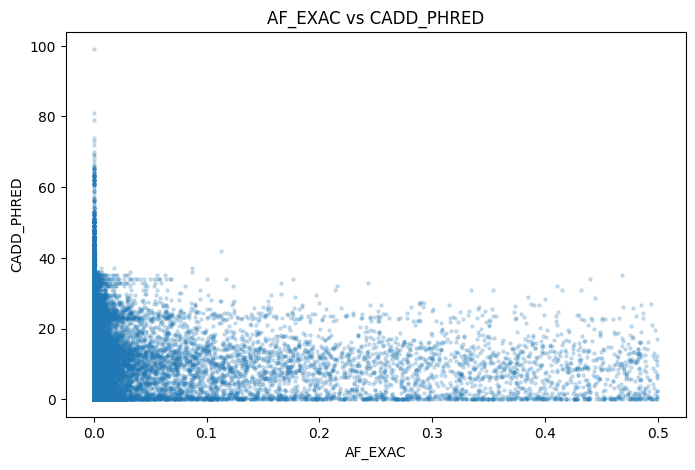

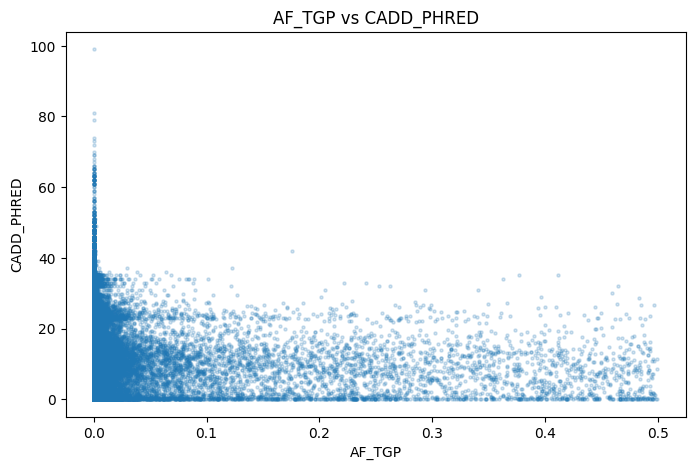

Variables: AF_EXAC and CADD_PHRED
Pearson: -0.1549
Spearman: -0.2322

Variables: AF_TGP and CADD_PHRED
Pearson: -0.1671
Spearman: -0.2621



In [35]:
# 6.1 Relationships Between Numerical Variables

import matplotlib.pyplot as plt

pairs = [
    ("AF_EXAC", "CADD_PHRED"),
    ("AF_TGP", "CADD_PHRED")
]

for x, y in pairs:
    data = df_clean[[x, y]].dropna()

    plt.figure(figsize=(8, 5))
    plt.scatter(data[x], data[y], alpha=0.2, s=5)
    plt.title(x + " vs " + y)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

    # Correlation Analysis

for x, y in pairs:
    data = df_clean[[x, y]].dropna()

    pearson = data[x].corr(data[y], method="pearson")
    spearman = data[x].corr(data[y], method="spearman")

    print("Variables:", x, "and", y)
    print("Pearson:", round(pearson, 4))
    print("Spearman:", round(spearman, 4))
    print()

### 6.1 Relationships Between Numerical Variables

We examined two pairs of numerical variables: `AF_EXAC` and `CADD_PHRED`, and `AF_TGP` and `CADD_PHRED`.

For each pair, we created a scatter plot and calculated Pearson and Spearman correlation coefficients.

**1. AF_EXAC and CADD_PHRED**

The Pearson correlation coefficient was **-0.1549**, indicating a weak negative linear relationship.

The Spearman correlation coefficient was **-0.2322**, indicating a somewhat stronger, but still weak, negative monotonic relationship.

The scatter plot shows that most genetic variants have very low population frequencies. Variants with higher predicted harmfulness scores are mainly concentrated at low frequencies, although many low-frequency variants also have low scores.

**2. AF_TGP and CADD_PHRED**

The Pearson correlation coefficient was **-0.1671**, indicating a weak negative linear relationship.

The Spearman correlation coefficient was **-0.2621**, indicating a somewhat stronger negative monotonic relationship.

The scatter plot shows a similar pattern, with higher harmfulness scores appearing mainly among variants with low population frequencies.

**Comparison Between the Correlation Measures**

In both pairs, Spearman produced a stronger negative correlation than Pearson. This suggests that the negative monotonic relationship is more noticeable than the linear relationship.

The correlations were slightly stronger for `AF_TGP` than for `AF_EXAC`.

**Overall Conclusion**

Both pairs show evidence of a weak negative association between population frequency and predicted harmfulness.

This suggests that rarer genetic variants tend to have higher predicted harmfulness scores. However, the correlations are relatively weak, meaning that population frequency alone cannot reliably predict a variant's harmfulness score.

These findings provide initial support for our second research question, but they do not establish a causal relationship.

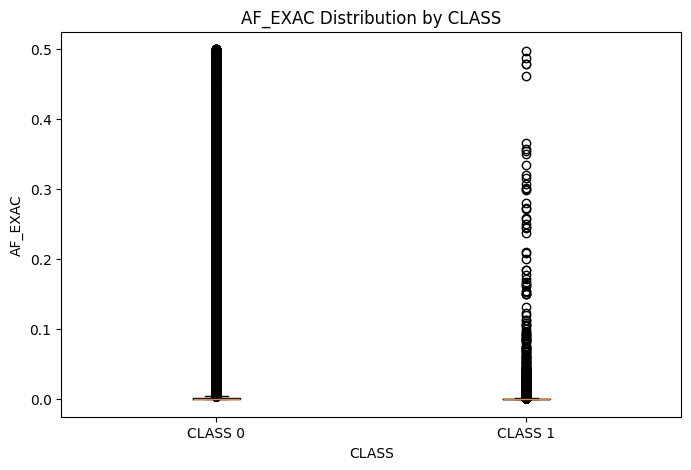

,count,mean,median,std
CLASS,,,,
0,48754,0.01868,0.00003,0.06775
1,16434,0.00206,0.00017,0.01541


In [37]:
# 6.2 Categorical and Numerical Variables

import matplotlib.pyplot as plt

# Divide the data into two groups
group_0 = df_clean[df_clean["CLASS"] == 0]["AF_EXAC"]
group_1 = df_clean[df_clean["CLASS"] == 1]["AF_EXAC"]

# Create Boxplot
plt.figure(figsize=(8, 5))
plt.boxplot([group_0, group_1], tick_labels=["CLASS 0", "CLASS 1"])
plt.title("AF_EXAC Distribution by CLASS")
plt.xlabel("CLASS")
plt.ylabel("AF_EXAC")
plt.show()

# Compare descriptive statistics
stats = df_clean.groupby("CLASS")["AF_EXAC"].agg(
    ["count", "mean", "median", "std"]
)

display(stats.round(5))

### 6.2 Relationship Between a Categorical and a Numerical Variable

We selected `CLASS` as the categorical variable and `AF_EXAC` as the numerical variable to examine whether population frequency differs between genetic variants with and without conflicting clinical classifications.

We used a boxplot to compare the distributions and calculated descriptive statistics for each group.

**CLASS = 0 (No Conflicting Classifications)**

This group contains 48,754 observations. The mean `AF_EXAC` value is 0.01868, the median is 0.00003, and the standard deviation is 0.06775.

**CLASS = 1 (Conflicting Classifications)**

This group contains 16,434 observations. The mean `AF_EXAC` value is 0.00206, the median is 0.00017, and the standard deviation is 0.01541.

**Comparison Between the Groups**

The mean population frequency is considerably higher in `CLASS = 0`, while the median is higher in `CLASS = 1`.

This difference suggests that the distribution is strongly right-skewed, particularly in `CLASS = 0`, where higher frequency values increase the mean.

The boxplot shows that most observations in both groups are concentrated near zero, but `CLASS = 0` has a wider spread and more high-frequency observations.

**Overall Conclusion**

The results indicate differences in the distribution of population frequencies between variants with and without conflicting clinical classifications.

However, because the mean and median show different patterns, we cannot conclude that one group consistently has higher population frequencies.

These findings are relevant to our third research question and suggest that the relationship between population frequency and conflicting clinical classifications requires further investigation.

In [38]:
# 6.3 Research Question - Correlation by CLASS

columns = ["AF_EXAC", "CADD_PHRED"]

# Overall correlations
data = df_clean[columns].dropna()

print("Overall:")
print("Pearson:", round(data.corr().iloc[0, 1], 4))
print("Spearman:", round(data.corr(method="spearman").iloc[0, 1], 4))

# Correlations within each CLASS group
for group in [0, 1]:
    data = df_clean[df_clean["CLASS"] == group][columns].dropna()

    print("\nCLASS =", group)
    print("Number of observations:", len(data))
    print("Pearson:", round(data.corr().iloc[0, 1], 4))
    print("Spearman:", round(data.corr(method="spearman").iloc[0, 1], 4))

Overall:
Pearson: -0.1549
Spearman: -0.2322

CLASS = 0
Number of observations: 47792
Pearson: -0.1825
Spearman: -0.2652

CLASS = 1
Number of observations: 16304
Pearson: -0.0222
Spearman: -0.0634


### 6.3 Research Question – Does the Overall Correlation Tell the Whole Story?

We selected the relationship between `AF_EXAC` (population frequency) and `CADD_PHRED` (predicted harmfulness score), which showed a weak negative correlation in Section 6.1.

To investigate whether this relationship remains consistent across different groups, we divided the dataset according to `CLASS`:

- `CLASS = 0`: Genetic variants without conflicting clinical classifications.
- `CLASS = 1`: Genetic variants with conflicting clinical classifications.

We calculated Pearson and Spearman correlations for the entire dataset and separately for each group.

| Group | Observations | Pearson | Spearman |
|---|---:|---:|---:|
| Overall | 64,096 | -0.1549 | -0.2322 |
| CLASS = 0 | 47,792 | -0.1825 | -0.2652 |
| CLASS = 1 | 16,304 | -0.0222 | -0.0634 |

**Comparison of the Results**

The overall dataset shows a weak negative relationship between population frequency and predicted harmfulness.

In `CLASS = 0`, the negative relationship is slightly stronger than in the overall dataset.

However, in `CLASS = 1`, both correlation coefficients are close to zero, indicating little evidence of a linear or monotonic relationship.

**Does the Overall Correlation Tell the Whole Story?**

No. The overall correlation hides important differences between the two groups. The negative relationship is more noticeable among variants without conflicting clinical classifications, while it is almost absent among variants with conflicting classifications.

Although the direction of the correlations does not reverse, their strengths differ substantially between the groups.

**Conclusion**

The relationship between population frequency and predicted harmfulness is not equally strong across the two `CLASS` groups.

These findings demonstrate why examining correlations within subgroups is important, rather than relying only on the overall correlation.

Finally, correlation does not imply causation. The observed relationships do not prove that population frequency causes changes in predicted harmfulness or that clinical classification conflicts cause the differences between the groups.

In [39]:
# 7. Robustness Check

data = df_clean[["AF_EXAC", "CADD_PHRED"]].dropna()

Q1 = data["CADD_PHRED"].quantile(0.25)
Q3 = data["CADD_PHRED"].quantile(0.75)
IQR = Q3 - Q1

filtered = data[data["CADD_PHRED"].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)]

print("Original Pearson:", round(data.corr().iloc[0, 1], 4))
print("Filtered Pearson:", round(filtered.corr().iloc[0, 1], 4))

print("Original Spearman:", round(data.corr(method="spearman").iloc[0, 1], 4))
print("Filtered Spearman:", round(filtered.corr(method="spearman").iloc[0, 1], 4))

print("Removed outliers:", len(data) - len(filtered))

Original Pearson: -0.1549
Filtered Pearson: -0.1555
Original Spearman: -0.2322
Filtered Spearman: -0.2302
Removed outliers: 131


### 7. Robustness Check

**Original Conclusion**

In Section 6.1, we found a weak negative relationship between population frequency (`AF_EXAC`) and predicted harmfulness (`CADD_PHRED`). The Pearson correlation was -0.1549, and the Spearman correlation was -0.2322.

This suggested that rarer genetic variants tend to have higher predicted harmfulness scores.

**Experiment 1 – Removing Outliers**

We removed 131 observations identified as outliers in `CADD_PHRED` using the IQR method and recalculated the correlations.

| Measure | Original | Without Outliers |
|---|---:|---:|
| Pearson | -0.1549 | -0.1555 |
| Spearman | -0.2322 | -0.2302 |

The results changed only slightly. Both correlations remained negative and weak, suggesting that the original relationship is not primarily driven by these outliers.

**Experiment 2 – Comparing Different Groups**

We compared the correlations separately for `CLASS = 0` and `CLASS = 1`, using the results from Section 6.3.

| Group | Pearson | Spearman |
|---|---:|---:|
| CLASS = 0 | -0.1825 | -0.2652 |
| CLASS = 1 | -0.0222 | -0.0634 |

The negative relationship was more noticeable in `CLASS = 0`, while both correlations were close to zero in `CLASS = 1`.

This shows that the overall correlation hides important differences between groups.

**Final Conclusion – Do We Still Support the Original Conclusion?**

We partially support our original conclusion.

The negative relationship remained almost unchanged after removing outliers, indicating that it is robust to this particular change in the analysis.

However, the relationship was not consistent across the two `CLASS` groups. It was more noticeable among variants without conflicting clinical classifications and almost absent among variants with conflicting classifications.

Therefore, we conclude that there is a weak negative association between population frequency and predicted harmfulness in the overall dataset, but this relationship should not be generalized equally to all subgroups.

These results demonstrate the importance of testing conclusions under different conditions. They also do not establish a causal relationship.

In [40]:
# 8. Independent Implementation

data = df_clean["AF_EXAC"]

# Calculate mean
total = 0
for value in data:
    total = total + value

mean = total / len(data)

# Calculate population variance
total_squared = 0
for value in data:
    total_squared = total_squared + (value - mean)**2

variance = total_squared / len(data)

# Calculate standard deviation
std = variance**0.5

# Compare with Pandas
print("Manual mean:", mean)
print("Pandas mean:", data.mean())

print("Manual variance:", variance)
print("Pandas variance:", data.var(ddof=0))

print("Manual standard deviation:", std)
print("Pandas standard deviation:", data.std(ddof=0))

Manual mean: 0.014492175400379639
Pandas mean: 0.014492175400380437
Manual variance: 0.003545206849582874
Pandas variance: 0.003545206849582874
Manual standard deviation: 0.059541639627934954
Pandas standard deviation: 0.059541639627934954


### 8. Independent Implementation in Python

We selected `AF_EXAC`, a numerical variable with no missing values.

We independently calculated the mean and population variance using Python loops, without using the built-in statistical functions. We then calculated the standard deviation as the square root of the population variance.

We compared our results with the built-in Pandas functions, using `ddof=0` to calculate population variance and standard deviation.

| Measure | Manual Calculation | Pandas |
|---|---:|---:|
| Mean | 0.014492175400379639 | 0.014492175400380437 |
| Population Variance | 0.003545206849582874 | 0.003545206849582874 |
| Standard Deviation | 0.059541639627934954 | 0.059541639627934954 |

**Results and Explanation**

The manual calculations and Pandas results were nearly identical. The mean showed an extremely small difference due to floating-point precision and differences in numerical computation.

The population variance and standard deviation matched exactly at the displayed precision.

**Conclusion**

Our independent implementation was successful and produced results consistent with Pandas. The negligible difference in the mean is due to numerical precision rather than an error in the calculation.

4. Research Questions
The three research questions I would like to investigate using this dataset are:

Are different types of genetic variants associated with different diseases?

Do rare genetic variants tend to have higher predicted harmfulness scores compared to common genetic variants?

Is there a relationship between the frequency of a genetic variant in the population and the presence of conflicting clinical classifications?